<h1>Conditional Routing in LangGraph</h1>

<h5>Creating the Graph with Conditional Edges

Edges connect the nodes.

Normal Edges are used if you want to always go from, for example, node_1 to node_2.

Conditional Edges are used want to optionally route between nodes.

Conditional edges are implemented as functions that return the next node to visit based upon some logic.<h5>

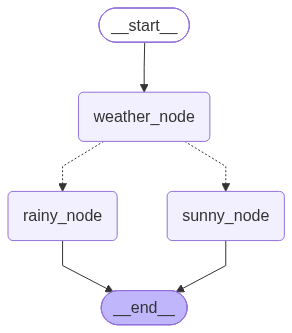

In [22]:
from typing import TypedDict
from langgraph.graph import StateGraph,START, END
from IPython.display import display, Image
# Define the state structure
class State(TypedDict):
    weather: str
#initialize the state graph
graph_builder = StateGraph(State)

#Define the nodes
def weather_node_df(state: State) -> State:
    print("Weather Node: Checking the weather...")
    return state

def rainy_node_df(state: State) -> State:
    print("Rainy Node: It's raining! Don't forget your umbrella.")
    return state

def sunny_node_df(state: State) -> State:
    print("Sunny Node: It's sunny! Enjoy the sunshine.")
    return state

#define the conditional routing function
def weather_routing(state: State) -> str:
    if state.get("weather") == "rainy":
        return "rainy_node"
    elif state.get("weather") == "sunny":
        return "sunny_node"
    else:
        raise ValueError("Unknown weather condition")

#Add nodes to the graph
graph_builder.add_node("weather_node", weather_node_df)
graph_builder.add_node("rainy_node", rainy_node_df)
graph_builder.add_node("sunny_node", sunny_node_df)    

#define the edges
graph_builder.add_edge(START, "weather_node")

#Add conditional edges based on the weather condition

graph_builder.add_conditional_edges("weather_node", 
                                    # the routing function will route to the rainy node if weather state is 'rainy'
                                    # the routing function will route to the sunny node if the weather state is 'sunny'
                                   weather_routing,
                                   ["rainy_node", "sunny_node"]
                                   )

graph_builder.add_edge("rainy_node", END)

graph_builder.add_edge("sunny_node", END)

#complie the graph
graph = graph_builder.compile()
display(Image(graph.get_graph().draw_mermaid_png()))


In [23]:
# Execute the graph with an initial state for "rainy"
print("\n--- Rainy Condition ---")
initial_state_rainy = {"weather": "rainy"}
result_rainy = graph.invoke(initial_state_rainy)


--- Rainy Condition ---
Weather Node: Checking the weather...
Rainy Node: It's raining! Don't forget your umbrella.


In [24]:
# Execute the graph with an initial state for "sunny"
print("\n--- Sunny Condition ---")
initial_state_sunny = {"weather": "sunny"}
result_sunny = graph.invoke(initial_state_sunny)


--- Sunny Condition ---
Weather Node: Checking the weather...
Sunny Node: It's sunny! Enjoy the sunshine.


In [25]:
# This will throw an error
print("\n--- Sunny Condition ---")
initial_state_sunny = {"weather": "humid"}
result_sunny = graph.invoke(initial_state_sunny)


--- Sunny Condition ---
Weather Node: Checking the weather...


ValueError: Unknown weather condition